### Explore HypoMap data characteristics

#### preparation

load modules:

In [14]:
import scanpy as sc
import pandas as pd

In [4]:
%load_ext lab_black

set paths:

In [2]:
hypomap_path = "../data/hypoMap_anndata.h5ad"

read files:

In [3]:
adata = sc.read(hypomap_path)

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_basic/lib/python3.7/site-packages/anndata/compat/__init__.py:235: FutureWarning: Moving element from .uns['neighbors']['distances'] to .obsp['distances'].

This is where adjacency matrices should go now.
  FutureWarning,


#### exploration

In [5]:
adata

AnnData object with n_obs × n_vars = 384925 × 57362
    obs: 'Cell_ID', 'Dataset', 'SRA_ID', 'Sample_ID', 'GEO_ID', 'Run10x', 'Technology', 'Strain', 'Diet', 'Pooled', 'Age', 'Author_Region', 'inferred_sex', 'nCount_RNA', 'nFeature_RNA', 'percent_mt', 'Author_Exclude', 'Author_Class', 'Author_CellType', 'percent_exclude_features', 'S.Score', 'G2M.Score', 'Phase', 'Batch_ID', 'Author_Condition', 'Sex', 'Author_Batch', 'Author_Class_Curated', 'C2', 'C7', 'C25', 'C66', 'C185', 'C286', 'C465', 'C2_named', 'C7_named', 'C25_named', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'Region_predicted', 'Region_summarized'
    var: 'features'
    uns: 'neighbors'
    obsm: 'X_scvi', 'X_umap_scvi'
    obsp: 'distances'

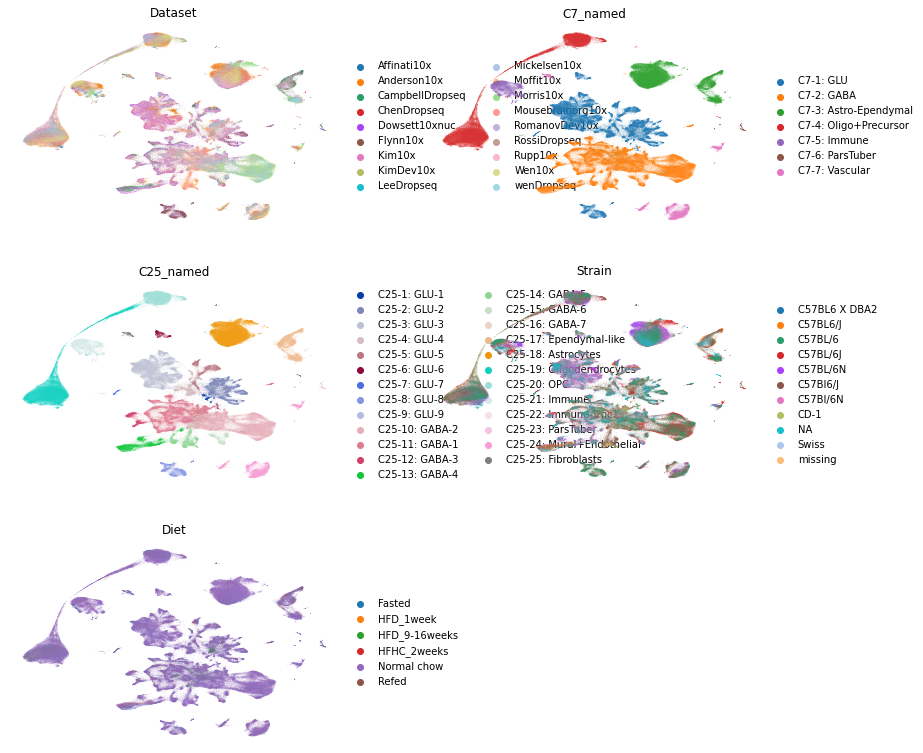

In [8]:
sc.pl.embedding(
    adata,
    basis="X_umap_scvi",
    color=["Dataset", "C7_named", "C25_named", "Strain", "Diet"],
    frameon=False,
    ncols=2,
)

Check diet values:

In [9]:
adata.obs.Diet.value_counts()

Normal chow      351669
Fasted            21011
HFD_9-16weeks      4659
HFD_1week          3611
HFHC_2weeks        2212
Refed              1763
Name: Diet, dtype: int64

**Keep: normal chow** = normal/control<br>
**Exclude all others.** Acronym info: hfd = high fat diet, hfhc = high fat high cholesterol, refed = fasted with subsequent re-feeding 

**Author_Conditions** notes:<br>
   - Mousebrainorg10x, Ad06, Ad18, Ad25, Ad33, Ad36. Paper does not mention any special mouse conditions, so ok to ignore.
   - wenDropseq, CT14, CT18, CT22 etc. These are different circadian rhythm time points, I think we will consider these normal for the purpose of our experiment? Unclear what flash is, likely treated with alternating light and darkness. Maybe check if they have very low mixing scores. Also note that they are pooled samples (5 mice per time point...), but information on individuals is not included in the atlas, so we'll have to consider them single samples...
   - Rupp10x, **"Insulin"**: unclear from preprint, but **take out** to be sure
   - Kim10x, "Control..." and "Plain..." indicate different ways of moving mice to new location, "F" indicates females. Naive indicates sexually naive, exp is experienced. I'd also say treat all as normal.
   

**Author_Exlude**: these are cells that did not pass original authors' QC, but that did pass HypoMap reanalysis QC. Will stick with HypoMap selection, so just keep all cells.

In [49]:
adata.obs.Author_Exclude.value_counts()

no     264985
NA      91471
yes     28469
Name: Author_Exclude, dtype: int64

Final note: note that in the atlas there is **no information regarding e.g. knock-out mice**, so there might still be some abnormal mice in there...

**Normalization method** was: log((count/total_counts * 10\**4) + 1), as illustrated by the reverse below:

In [84]:
cell_number = 7230  # choose random cell number

In [85]:
raw_counts = (
    np.expm1(adata.X[cell_number, :]) / 10**4 * adata.obs.nCount_RNA[cell_number]
)

should be True:

In [86]:
adata.obs.nCount_RNA[cell_number] == raw_counts.sum()

True

should contain integers only (barring rounding errors):

In [87]:
raw_counts[0, :50].toarray()

array([[0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0.]])

In [88]:
adata.obs.Age.value_counts()

6+ weeks     215577
NA            84229
0-3 weeks     44814
3-6 weeks     40305
Name: Age, dtype: int64